# Práctica 3 (Tópico 3): Diseño de un Experimento de Ubicación de Producto
**Caso RetailAndina S.A. · IDSD422 · Estadística y Programación para Ciencia de Datos I · 2026-B**

Este cuaderno contiene la implementación completa y verificada bloque a bloque del protocolo experimental:
1. **Exploración de la plantilla base (`registro_experimento.csv`)** y análisis de sus limitaciones estadísticas (Sección 9).
2. **Diseño cruzado aleatorizado (`AB/BA`)** con semilla reproducible (`1234597`) sobre $N = 40$ unidades semana-tienda.
3. **Simulación de ventas semanales** con semilla (`1234598`), efectos por tienda/semana y registro de promoción simultánea.
4. **Análisis pareado intratienda**, prueba de hipótesis ($t$ pareada) y visualización comparativa.

## Bloque 1: Carga y exploración de la plantilla base (`registro_experimento.csv`)
Se corrige la ruta de lectura para que funcione tanto desde la raíz del repositorio como desde `scripts/`, se calcula el promedio de `ventas_producto` por `ubicacion`, se contabilizan los registros por grupo y se documentan los límites de trabajar con solo 4 observaciones.

In [1]:
import os
import pandas as pd
import numpy as np

# Resolución automática de ruta según el directorio de trabajo (raíz o carpeta scripts/)
posibles_rutas = [
    "plantillas/registro_experimento.csv",
    "../plantillas/registro_experimento.csv",
    "IDSD422-lab3-diseno-experimento/plantillas/registro_experimento.csv"
]
ruta_csv = next((r for r in posibles_rutas if os.path.exists(r)), posibles_rutas[0])

df = pd.read_csv(ruta_csv)
print(f"Archivo cargado desde: {ruta_csv}")
print(df)

print("\nPromedio de ventas_producto por ubicacion:")
print(df.groupby("ubicacion")["ventas_producto"].mean())

print("\nNúmero de registros por grupo:")
print(df["ubicacion"].value_counts())

print("\nInterpretación (Sección 9):")
print(
    "Con solo 4 filas (2 observaciones por grupo), el promedio por ubicación no prueba causalidad: "
    "la muestra carece de potencia estadística, no permite estimar adecuadamente la varianza "
    "intragrupo y confunde las diferencias estructurales entre tiendas y semanas con el efecto del tratamiento."
)

Archivo cargado desde: plantillas/registro_experimento.csv
             tienda  semana          ubicacion  ventas_producto promocion_simultanea
0       Quito Norte       1           habitual             1020                   no
1       Quito Norte       2  pasillo_principal             1280                   no
2  Guayaquil Centro       1  pasillo_principal             1510                   no
3  Guayaquil Centro       2           habitual             1240                   no

Promedio de ventas_producto por ubicacion:
ubicacion
habitual             1130.0
pasillo_principal    1395.0
Name: ventas_producto, dtype: float64

Número de registros por grupo:
ubicacion
habitual             2
pasillo_principal    2
Name: count, dtype: int64

Interpretación (Sección 9):
Con solo 4 filas (2 observaciones por grupo), el promedio por ubicación no prueba causalidad: la muestra carece de potencia estadística, no permite estimar adecuadamente la varianza intragrupo y confunde las diferencias estru

## Bloque 2: Diseño cruzado aleatorizado (Asignación de unidades semana-tienda)
Se definen **10 sucursales** de RetailAndina S.A. observadas durante **4 semanas consecutivas** ($N = 40$ unidades experimentales `semana-tienda`). Mediante la semilla `1234597`, se sortea la condición inicial (`pasillo_principal` o `habitual`) para las semanas impares (1 y 3) y se alterna a la condición opuesta en las semanas pares (2 y 4).

In [2]:
# Definición de sucursales y horizonte temporal
tiendas = [
    "Quito Norte", "Quito Sur", "Guayaquil Centro", "Guayaquil Norte",
    "Cuenca Centro", "Cuenca Sur", "Ambato Centro", "Manta", "Loja", "Machala"
]
semanas = [1, 2, 3, 4]

# Sorteo reproducible de la condición inicial (Semilla 1234597)
rng = np.random.default_rng(1234597)
primera = rng.choice(["pasillo_principal", "habitual"], size=len(tiendas))

filas = []
for tienda, cond in zip(tiendas, primera):
    otra = "habitual" if cond == "pasillo_principal" else "pasillo_principal"
    for s in semanas:
        filas.append({
            "tienda": tienda,
            "semana": s,
            "ubicacion": cond if s % 2 == 1 else otra
        })

diseno = pd.DataFrame(filas)
print(f"Total de unidades experimentales (semana-tienda): N = {len(diseno)}")
print("\nBalance de unidades asignadas por nivel del factor:")
print(diseno["ubicacion"].value_counts())
print("\nAsignación por tienda (Semanas 1 a 4):")
print(diseno.pivot(index="tienda", columns="semana", values="ubicacion"))

Total de unidades experimentales (semana-tienda): N = 40

Balance de unidades asignadas por nivel del factor:
ubicacion
habitual             20
pasillo_principal    20
Name: count, dtype: int64

Asignación por tienda (Semanas 1 a 4):
semana                            1                  2                  3                  4
tienda                                                                                      
Ambato Centro              habitual  pasillo_principal           habitual  pasillo_principal
Cuenca Centro     pasillo_principal           habitual  pasillo_principal           habitual
Cuenca Sur                 habitual  pasillo_principal           habitual  pasillo_principal
Guayaquil Centro           habitual  pasillo_principal           habitual  pasillo_principal
Guayaquil Norte   pasillo_principal           habitual  pasillo_principal           habitual
Loja                       habitual  pasillo_principal           habitual  pasillo_principal
Machala           pasi

## Bloque 3: Simulación de la ejecución experimental y registro de covariables
*(Corrección respecto al borrador inicial: se reemplazan los paréntesis/operadores erróneos en `efecto_semana = {1: 0, 2: 30, 3: 60, 4: 90}` y las llaves en `diseno["ventas_producto"]` por sintaxis válida de Python/Pandas).*  
Se incorporan:
- **Efecto basal por tienda**: $\mathcal{N}(1100, 120^2)$.
- **Tendencia semanal**: incremento progresivo de $+30$ unidades por semana.
- **Efecto real del tratamiento (`pasillo_principal`)**: $+220$ unidades semanales.
- **Registro de evento confusor**: `promocion_simultanea = "si"` en *Guayaquil Centro* durante la semana 1 ($+180$ unidades adicionales).

In [3]:
# Simulación de ventas semanales con semilla fija (1234598)
rng_sim = np.random.default_rng(1234598)
efecto_tienda = dict(zip(tiendas, rng_sim.normal(1100, 120, len(tiendas))))
efecto_semana = {1: 0, 2: 30, 3: 60, 4: 90}

diseno["ventas_producto"] = (
    diseno["tienda"].map(efecto_tienda) +
    diseno["semana"].map(efecto_semana) +
    (diseno["ubicacion"] == "pasillo_principal") * 220 +
    rng_sim.normal(0, 90, len(diseno))
).round(0).astype(int)

# Registro de promoción simultánea como variable de control
diseno["promocion_simultanea"] = "no"
diseno.loc[(diseno["tienda"] == "Guayaquil Centro") & (diseno["semana"] == 1), "promocion_simultanea"] = "si"
diseno.loc[diseno["promocion_simultanea"] == "si", "ventas_producto"] += 180

# Exportar dataset simulado
carpeta_plantillas = os.path.dirname(ruta_csv) if os.path.dirname(ruta_csv) else "plantillas"
os.makedirs(carpeta_plantillas, exist_ok=True)
ruta_salida = os.path.join(carpeta_plantillas, "resultado_simulacion.csv")
diseno.to_csv(ruta_salida, index=False)

print(f"Dataset simulado guardado en: {ruta_salida}")
print(diseno.head(10))

Dataset simulado guardado en: plantillas/resultado_simulacion.csv
                                        tienda  semana          ubicacion  ventas_producto promocion_simultanea
typing.Literal[<no_default>]                                                                                   
0                                  Quito Norte       1           habitual              979                   no
1                                  Quito Norte       2  pasillo_principal             1380                   no
2                                  Quito Norte       3           habitual             1055                   no
3                                  Quito Norte       4  pasillo_principal             1259                   no
4                                    Quito Sur       1  pasillo_principal             1158                   no
5                                    Quito Sur       2           habitual              978                   no
6                                    Q

## Bloque 4: Análisis pareado intratienda e inferencia estadística
Dado que cada tienda funciona como su propio bloque experimental (2 semanas en `pasillo_principal` y 2 semanas en `habitual`), se calcula la diferencia pareada por sucursal ($d_i = \bar{Y}_{i,\text{pasillo}} - \bar{Y}_{i,\text{habitual}}$), su media global, desviación estándar y la prueba $t$ de Student para muestras pareadas.

In [4]:
from scipy import stats

# Promedio global sin parear
print("Promedio global por ubicación (N = 40):")
print(diseno.groupby("ubicacion")["ventas_producto"].mean().round(2))

# Análisis pareado por tienda
piv = diseno.groupby(["tienda", "ubicacion"])["ventas_producto"].mean().unstack()
piv["diferencia"] = piv["pasillo_principal"] - piv["habitual"]

media = piv["diferencia"].mean()
dev = piv["diferencia"].std(ddof=1)
t_stat, p_val = stats.ttest_rel(piv["pasillo_principal"], piv["habitual"])
ic_95 = stats.t.interval(0.95, df=len(piv)-1, loc=media, scale=stats.sem(piv["diferencia"]))

print("\nTabla comparativa pareada por tienda:")
print(piv.round(2))
print(f"\nPromedio de la diferencia pareada: {media:.2f} unidades/semana")
print(f"Desviación estándar de la diferencia: {dev:.2f} unidades/semana")
print(f"Estadístico t pareado (gl = {len(piv)-1}): t = {t_stat:.4f}, p-valor = {p_val:.6f}")
print(f"Intervalo de confianza del 95% para el efecto medio: [{ic_95[0]:.2f}, {ic_95[1]:.2f}] unidades/semana")

Promedio global por ubicación (N = 40):
ubicacion
habitual             1107.2
pasillo_principal    1346.9
Name: ventas_producto, dtype: float64

Tabla comparativa pareada por tienda:
ubicacion         habitual  pasillo_principal  diferencia
tienda                                                   
Ambato Centro       1071.5             1110.5        39.0
Cuenca Centro       1144.5             1256.0       111.5
Cuenca Sur          1227.5             1450.5       223.0
Guayaquil Centro    1366.5             1618.5       252.0
Guayaquil Norte     1098.0             1354.0       256.0
Loja                1027.5             1379.5       352.0
Machala             1071.0             1309.0       238.0
Manta               1030.5             1413.0       382.5
Quito Norte         1017.0             1319.5       302.5
Quito Sur           1018.0             1258.5       240.5

Promedio de la diferencia pareada: 239.70 unidades/semana
Desviación estándar de la diferencia: 102.39 unidades/semana
E

## Bloque 5: Visualización comparativa por sucursal
Gráfico de barras pareadas por tienda comparando el promedio semanal en `habitual` frente a `pasillo_principal`.

has vm saved


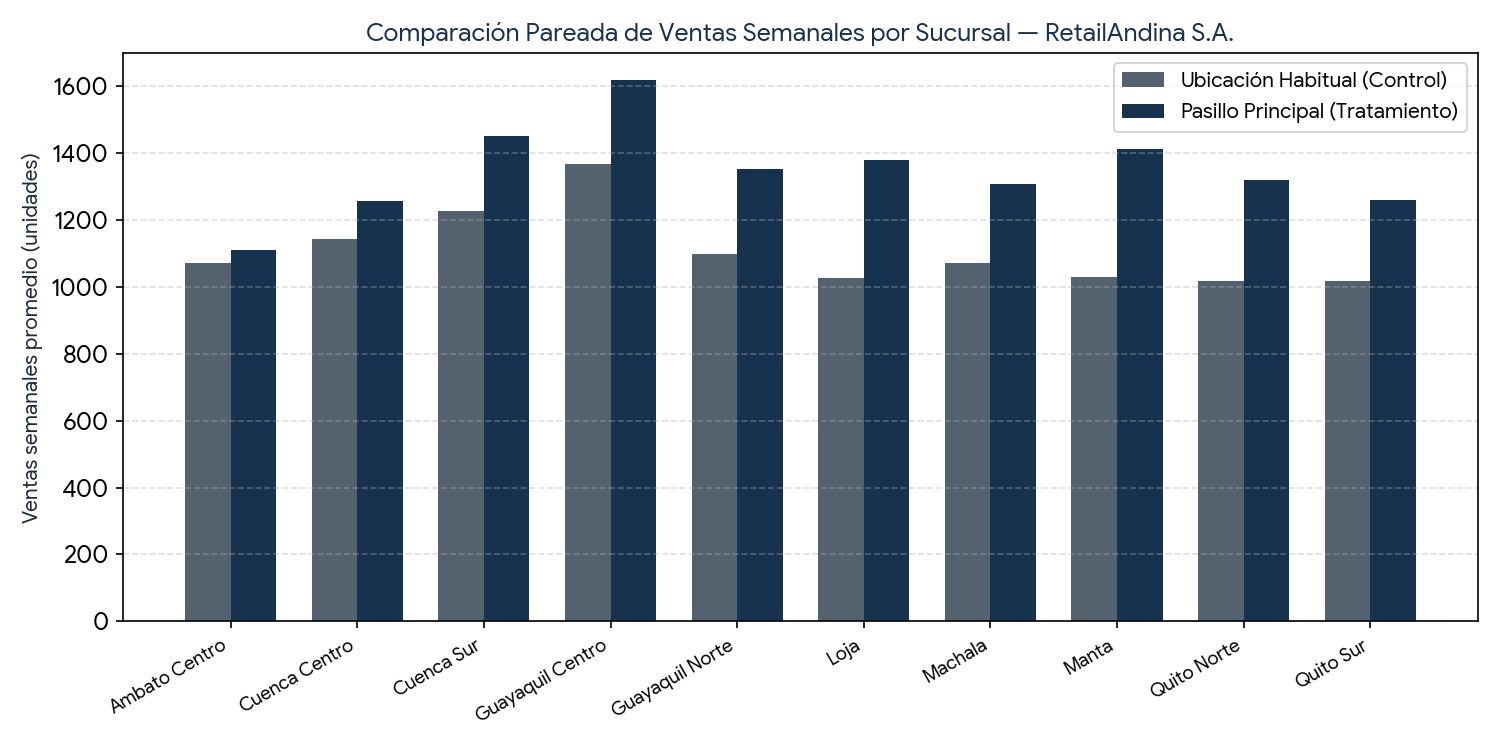

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(piv.index))
width = 0.36

rects1 = ax.bar(x - width/2, piv["habitual"], width, label="Ubicación Habitual (Control)", color="#54626F")
rects2 = ax.bar(x + width/2, piv["pasillo_principal"], width, label="Pasillo Principal (Tratamiento)", color="#16324E")

ax.set_ylabel("Ventas semanales promedio (unidades)", fontsize=10, color="#1B2A3A")
ax.set_title("Comparación Pareada de Ventas Semanales por Sucursal — RetailAndina S.A.", fontsize=12, fontweight="bold", color="#16324E")
ax.set_xticks(x)
ax.set_xticklabels(piv.index, rotation=30, ha="right", fontsize=9)
ax.legend(frameon=True)
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig("comparacion_ventas_pareadas.png", dpi=150)
plt.show()